# Live Detection Engine Prototype

End-to-end notebook for the mine-monitoring Live Risk Detection Engine.

**Pipeline:** sensor data → preprocessing → second/minute/hour features → threshold + trend + Isolation Forest → risk fusion → alerts.

The supplied dataset is synthetic. Nodes 4 and 5 contain the actual subsidence event; nodes 1–3 show milder nearby deterioration. **The numerical thresholds below are demonstration values, not real mine-safety limits.**

## 1. Setup

In [91]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass, field
from typing import List, Optional
from pathlib import Path
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

DATA_PATH = Path("../../data/Simulator_Gen_Synthetic/mine_sensor_5nodes_subsidence_nodes4_5.csv")
df = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])
df.drop( ['Unnamed: 11', 'Unnamed: 12'],axis=1, inplace=True)

print("Shape:", df.shape)
print("Nodes:", sorted(df.node_id.unique()))
df.head()

Shape: (432000, 11)
Nodes: ['NODE_01', 'NODE_02', 'NODE_03', 'NODE_04', 'NODE_05']


,node_id,timestamp,position_x,position_y,position_z,tilt_x,tilt_y,vibration_rms,vibration_peak,crack_width,scenario
0,NODE_01,2026-09-06 00:00:00+05:30,125,82,100.0,0.09762,0.06300,0.24092,0.60690,1.20750,normal
1,NODE_02,2026-09-06 00:00:00+05:30,140,82,99.5,0.10027,0.05247,0.28992,0.67556,1.20116,normal
2,NODE_03,2026-09-06 00:00:00+05:30,155,96,101.0,0.09661,0.06112,0.30255,0.77781,1.20308,normal
3,NODE_04,2026-09-06 00:00:00+05:30,170,96,100.5,0.09473,0.05817,0.29840,0.69053,1.19443,normal
4,NODE_05,2026-09-06 00:00:00+05:30,185,110,99.8,0.09598,0.05598,0.30880,0.61886,1.20863,normal


## 2. Inspect the dataset

In [92]:
print("ROWS PER NODE:")
print(df.groupby("node_id").size())
print("\nMISSING VALUES:")
print(df.isna().sum())
print("\nSENARIO COUNTS:")
print(df.groupby(["node_id", "scenario"]).size())

ROWS PER NODE:
node_id
NODE_01    86400
NODE_02    86400
NODE_03    86400
NODE_04    86400
NODE_05    86400
dtype: int64

MISSING VALUES:
node_id           0
timestamp         0
position_x        0
position_y        0
position_z        0
tilt_x            0
tilt_y            0
vibration_rms     0
vibration_peak    0
crack_width       0
scenario          0
dtype: int64

SENARIO COUNTS:
node_id  scenario     
NODE_01  deteriorating    32400
         normal           54000
NODE_02  deteriorating    30600
         normal           55800
NODE_03  deteriorating    28800
         normal           57600
NODE_04  deteriorating    30600
         normal           52200
         subsidence        3600
NODE_05  deteriorating    32400
         normal           48600
         subsidence        5400
dtype: int64


## 3. Data classes

These are the objects that will later become part of the production `../../engines/live` package.

In [93]:
@dataclass
class CleanSensorReading:
    """ Represents a single validated and preprocessed sensor reading received from a monitoring node in the mine.

    This is the standardized representation of sensor data passed
    from the preprocessing stage to the feature-engineering stage
    of the Live Risk Detection Engine.

    Attributes:
        node_id (str):
            Unique identifier of the sensor node that produced the reading.

        timestamp (pd.Timestamp):
            Date and time at which the sensor reading was recorded.

        position_x (float):
            X-coordinate of the sensor node within the mine's coordinate
            or spatial reference system.

        position_y (float):
            Y-coordinate of the sensor node within the mine's coordinate
            or spatial reference system.

        tilt_x (float):
            Measured ground/structure tilt along the X-axis.

        tilt_y (float):
            Measured ground/structure tilt along the Y-axis.

        vibration_rms (float):
            Root Mean Square (RMS) value of the measured vibration.

        vibration_peak (float):
            Peak vibration value measured during the sampling interval.

        crack_width (float):
            Measured width of a detected crack, typically expressed in
            millimetres or another unit defined by the sensor schema.
    """

    node_id: str
    timestamp: pd.Timestamp
    position_x: float
    position_y: float
    tilt_x: float
    tilt_y: float
    vibration_rms: float
    vibration_peak: float
    crack_width: float


@dataclass
class DetectorResult:
    """
    Represents the output produced by an individual risk detector.

    A detector may use threshold violations, sensor trends, anomaly
    detection models, or other detection logic. The result is passed
    to the risk-fusion stage, where outputs from multiple detectors
    are combined into an overall risk assessment.

    Attributes:
        detector (str):
            Name or identifier of the detector that produced the result.
            Examples include "threshold", "trend", or "anomaly".

        score (float):
            Normalized risk or anomaly score produced by the detector.
            The expected range is 0.0 to 1.0.

        triggered (bool):
            Indicates whether the detector considers the current
            sensor state significant enough to trigger its detection
            condition.

        reasons (List[str]):
            Human-readable explanations describing why the detector
            was or was not triggered. This information can be used
            when generating alerts and for debugging or auditing.
    """

    detector: str
    score: float
    triggered: bool
    reasons: List[str] = field(default_factory=list)


@dataclass
class RiskAssessment:
    """ Represents the combined risk assessment for a sensor node at a particular point in time.

    This object is produced by the risk-fusion stage after combining
    the outputs of multiple detection methods, such as threshold,
    trend, and machine-learning anomaly detectors.

    Attributes:
        node_id (str):
            Unique identifier of the sensor node for which the risk
            assessment was calculated.

        timestamp (pd.Timestamp):
            Date and time at which this risk assessment was generated.

        score (float):
            Combined risk score produced by the risk-fusion system.
            In this implementation, the score is represented on a
            scale from 0 to 100.

        severity (str):
            Human-readable classification of the current risk level.
            Expected values may include "NORMAL", "WATCH", "WARNING",
            or "CRITICAL".

        reasons (List[str]):
            Human-readable explanations collected from the individual
            detectors that contributed to the risk assessment.
    """

    node_id: str
    timestamp: pd.Timestamp
    score: float
    severity: str
    reasons: List[str] = field(default_factory=list)


@dataclass
class Alert:
    """
    Represents an alert generated by the Live Risk Detection Engine.

    An Alert is created when the calculated risk for a sensor node
    reaches a severity level that requires attention. It provides
    the information needed by the alert-management and downstream
    notification systems.

    Attributes:
        node_id (str):
            Unique identifier of the sensor node associated with
            the alert.

        timestamp (pd.Timestamp):
            Date and time at which the alert was generated.

        severity (str):
            Severity level of the alert, such as "WATCH", "WARNING",
            or "CRITICAL".

        risk_score (float):
            Overall risk score that caused the alert to be generated.
            In this implementation, the score is represented on a
            scale from 0 to 100.

        message (str):
            Human-readable description of the alert. This can be
            displayed on the monitoring dashboard or sent to an
            operator through a notification system.
    """

    node_id: str
    timestamp: pd.Timestamp
    severity: str
    risk_score: float
    message: str

## 4. Preprocessing and validation

In [94]:
SENSOR_COLUMNS = ["position_z","tilt_x", "tilt_y", "vibration_rms", "vibration_peak", "crack_width"]

def preprocess(data):
    out = data.copy()
    out = out.sort_values(["node_id", "timestamp"])
    out = out.drop_duplicates(["node_id", "timestamp"])

    # Non-numeric type inputs converted to numeric
    for col in SENSOR_COLUMNS:
        out[col] = pd.to_numeric(out[col], errors="coerce")

    # fills the missing value with a reasonable value based on nearby readings.
    out[SENSOR_COLUMNS] = out.groupby("node_id")[SENSOR_COLUMNS].transform(lambda x: x.interpolate(limit_direction="both"))

    # Remove rows that still contain missing values
    out = out.dropna(subset=["node_id", "timestamp"] + SENSOR_COLUMNS)
    return out.reset_index(drop=True)

clean_df = preprocess(df)
print("Rows after preprocessing:", len(clean_df))
print("Missing sensor values:", clean_df[SENSOR_COLUMNS].isna().sum().sum())

Rows after preprocessing: 432000
Missing sensor values: 0


## 5. Sensor visualization

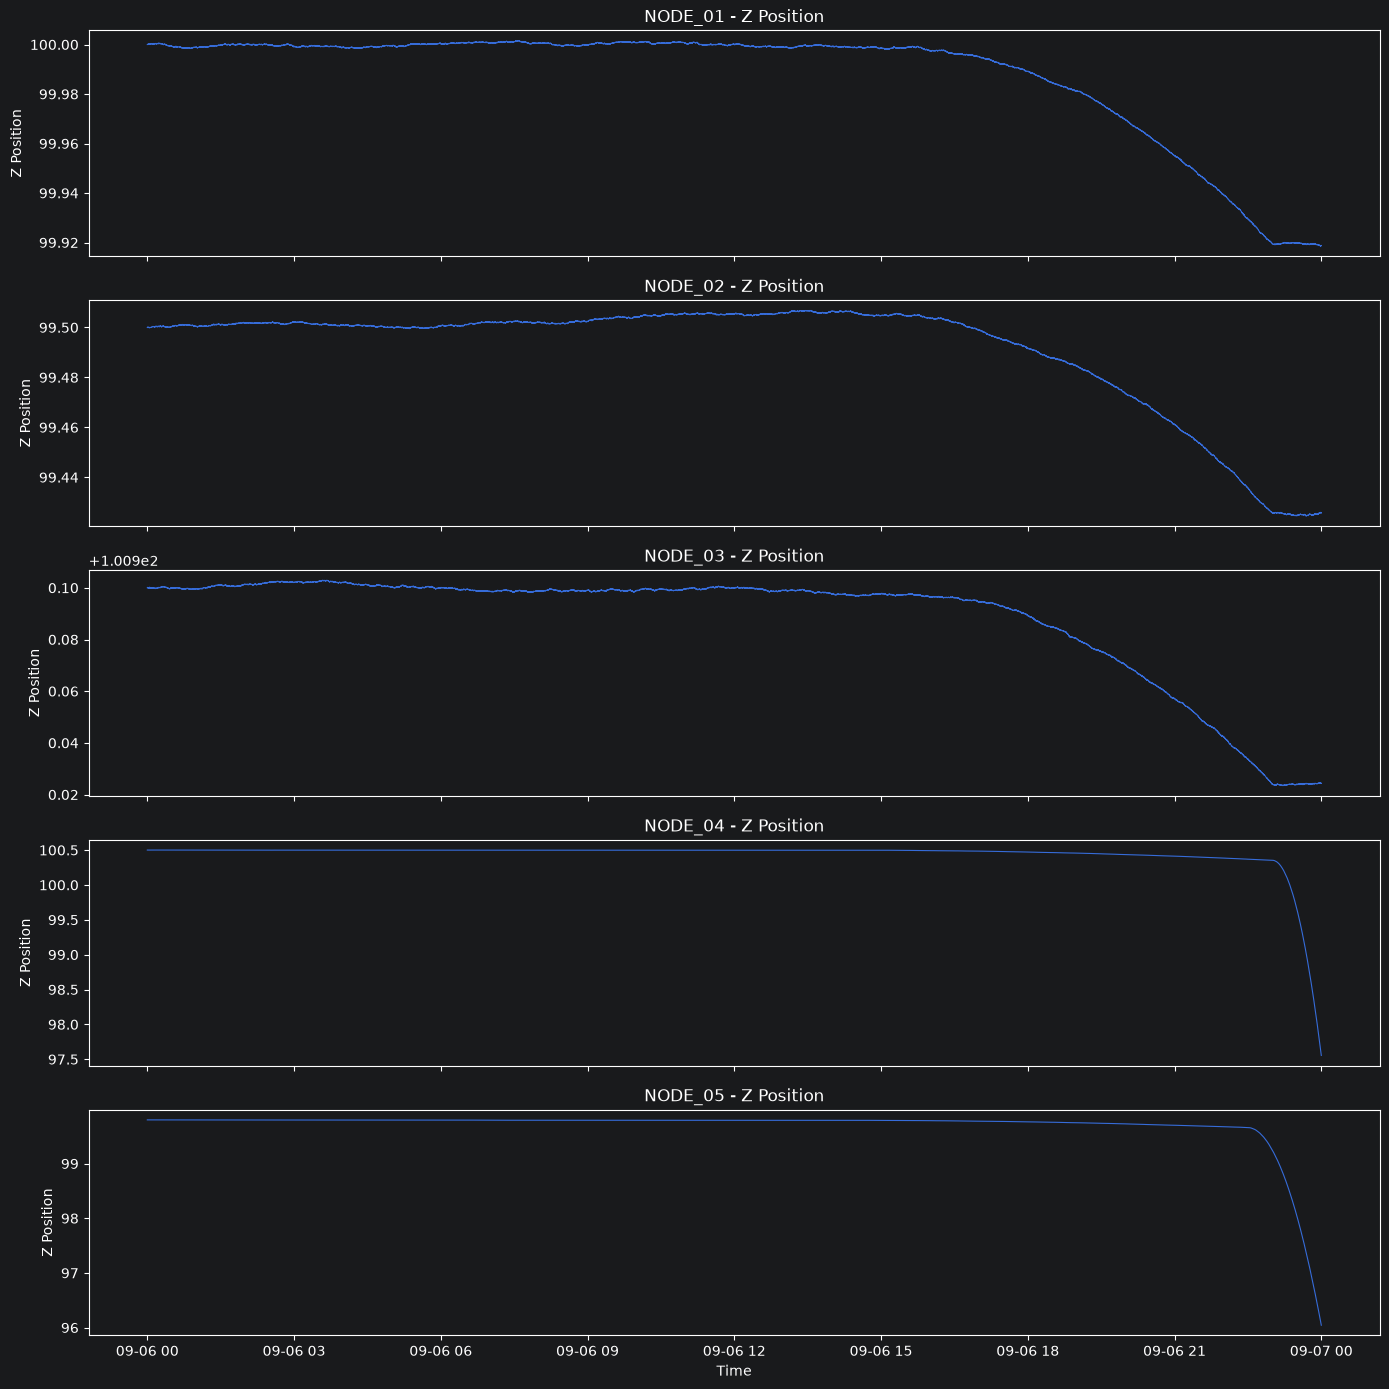

In [95]:
# Visualize Z-position of each sensor node over time

fig, axes = plt.subplots(
    5, 1,
    figsize=(14, 14),
    sharex=True
)

for ax, node in zip(axes, sorted(clean_df["node_id"].unique())):

    node_data = clean_df[
        clean_df["node_id"] == node
    ]

    ax.plot(
        node_data["timestamp"],
        node_data["position_z"],
        linewidth=0.8
    )

    ax.set_title(f"{node} - Z Position")
    ax.set_ylabel("Z Position")

axes[-1].set_xlabel("Time")

plt.tight_layout()
plt.show()

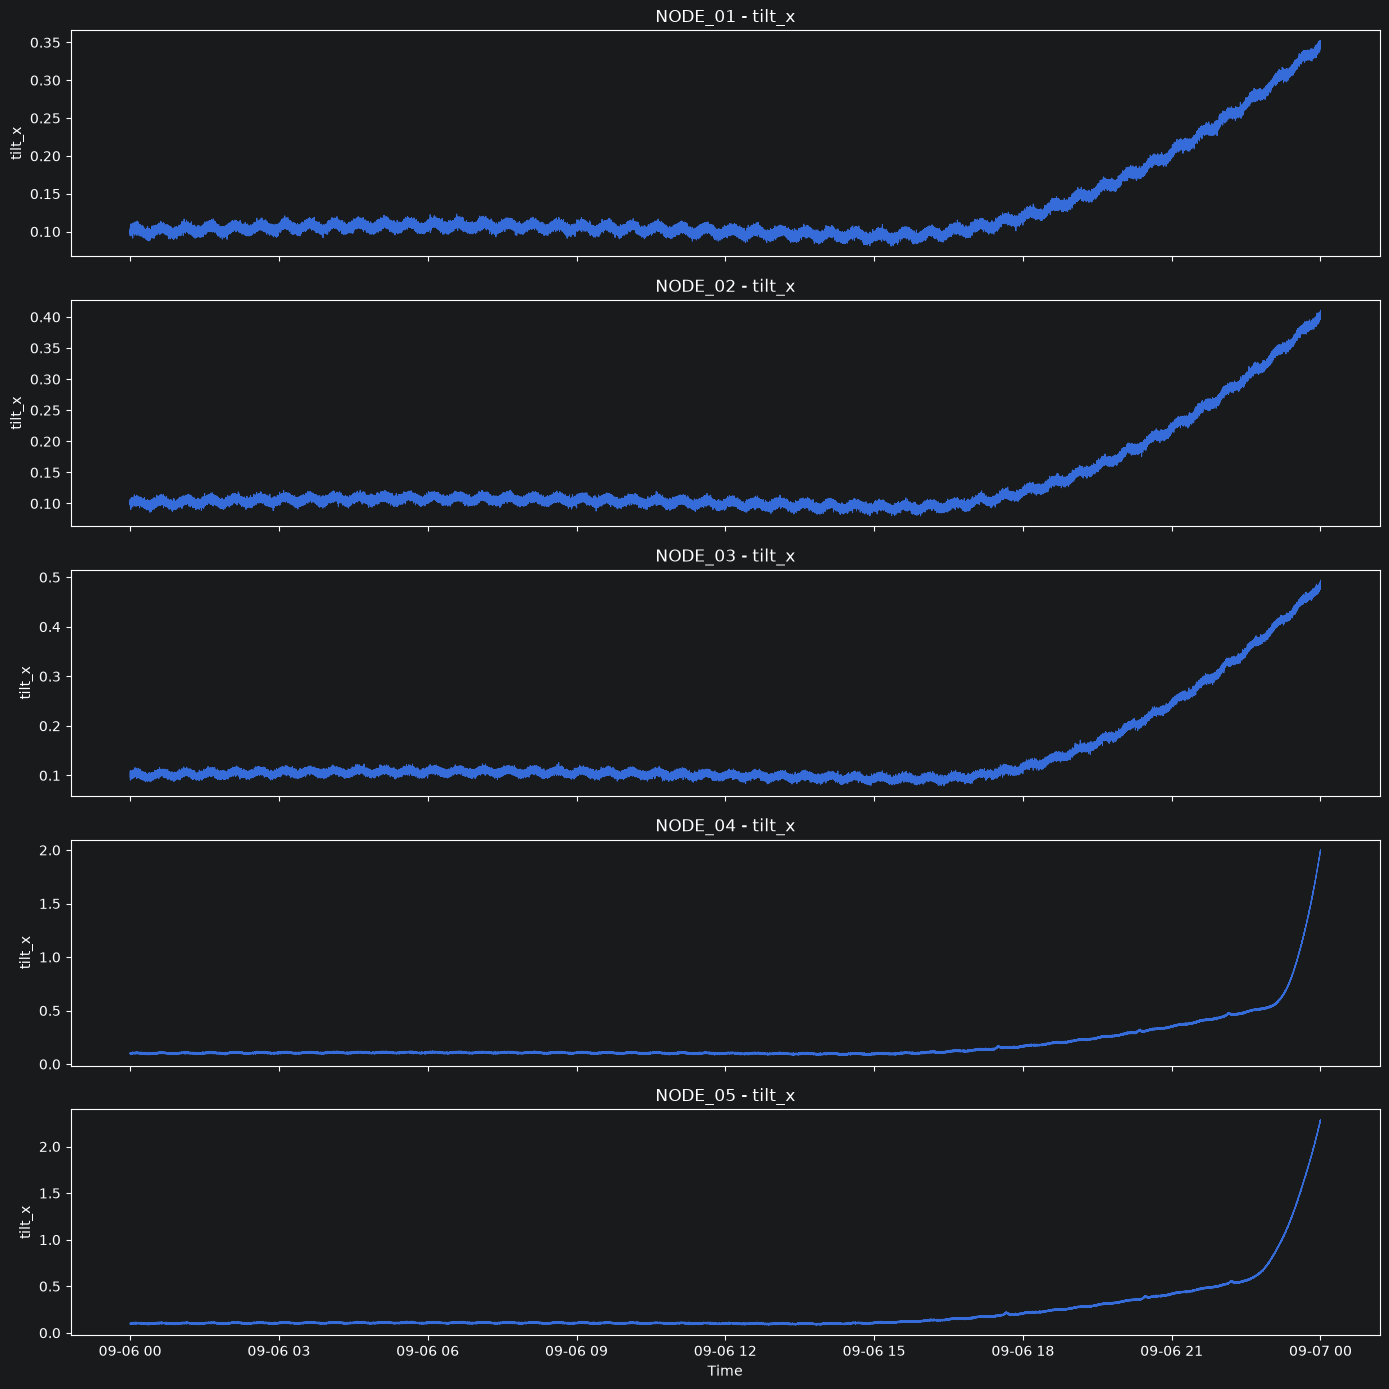

In [96]:
fig, axes = plt.subplots(5, 1, figsize=(14, 14), sharex=True)

for ax, node in zip(axes, sorted(clean_df.node_id.unique())):
    d = clean_df[clean_df.node_id == node]
    ax.plot(d.timestamp, d.tilt_x, linewidth=0.7)
    ax.set_title(f"{node} - tilt_x")
    ax.set_ylabel("tilt_x")

axes[-1].set_xlabel("Time")
plt.tight_layout()
plt.show()

## 6. Feature engineering

- **Second scale:** instantaneous rates.
- **Minute scale:** short-term changes
- **Hour scale:** longer-term changes.


In [97]:
def make_features(data):
    out = data.copy().sort_values(["node_id", "timestamp"])
    g = out.groupby("node_id")

    out["dt_sec"] = g.timestamp.diff().dt.total_seconds().fillna(1).clip(lower=1)

    # SECOND SCALE
    for col in ["position_z","tilt_x", "tilt_y", "crack_width"]:
        out[f"{col}_rate_sec"] = g[col].diff().fillna(0) / out.dt_sec

    # MINUTE SCALE
    for col in ["position_z","tilt_x", "tilt_y", "crack_width"]:
        out[f"{col}_change_1m"] = g[col].diff(60).fillna(0)

    out["vibration_mean_1m"] = g.vibration_rms.transform(
        lambda s: s.rolling(60, min_periods=1).mean()
    )
    out["vibration_std_1m"] = g.vibration_rms.transform(
        lambda s: s.rolling(60, min_periods=2).std()
    ).fillna(0)


    out["crack_growth_1m"] = out.crack_width_change_1m

    # HOUR SCALE
    for col in ["position_z","tilt_x", "tilt_y", "crack_width"]:
        out[f"{col}_change_1h"] = g[col].diff(3600).fillna(0)

    out["vibration_mean_1h"] = g.vibration_rms.transform(
        lambda s: s.rolling(3600, min_periods=1).mean()
    )
    out["vibration_std_1h"] = g.vibration_rms.transform(
        lambda s: s.rolling(3600, min_periods=2).std()
    ).fillna(0)

    out["crack_growth_1h"] = out.crack_width_change_1h


    # # 24-HOUR SCALE
    # out["position_z_change_24h"] = g.position_z.diff(86400).fillna(0)
    # out["tilt_x_change_24h"] = g.tilt_x.diff(86400).fillna(0)
    # out["tilt_y_change_24h"] = g.tilt_y.diff(86400).fillna(0)
    # out["crack_growth_24h"] = g.crack_width.diff(86400).fillna(0)

    return out.replace([np.inf, -np.inf], np.nan).fillna(0)

features_df = make_features(clean_df)
features_df.head()

,node_id,timestamp,position_x,position_y,position_z,tilt_x,tilt_y,vibration_rms,vibration_peak,crack_width,...,vibration_mean_1m,vibration_std_1m,crack_growth_1m,position_z_change_1h,tilt_x_change_1h,tilt_y_change_1h,crack_width_change_1h,vibration_mean_1h,vibration_std_1h,crack_growth_1h
0,NODE_01,2026-09-06 00:00:00+05:30,125,82,100.00000,0.09762,0.06300,0.24092,0.60690,1.20750,...,0.240920,0.000000,0.0,0.0,0.0,0.0,0.0,0.240920,0.000000,0.0
1,NODE_01,2026-09-06 00:00:01+05:30,125,82,100.00000,0.10074,0.06574,0.27453,0.64512,1.19943,...,0.257725,0.023766,0.0,0.0,0.0,0.0,0.0,0.257725,0.023766,0.0
2,NODE_01,2026-09-06 00:00:02+05:30,125,82,99.99998,0.09434,0.06364,0.29938,0.67805,1.19588,...,0.271610,0.029339,0.0,0.0,0.0,0.0,0.0,0.271610,0.029339,0.0
3,NODE_01,2026-09-06 00:00:03+05:30,125,82,100.00000,0.10423,0.05479,0.29823,0.81675,1.20265,...,0.278265,0.027405,0.0,0.0,0.0,0.0,0.0,0.278265,0.027405,0.0
4,NODE_01,2026-09-06 00:00:04+05:30,125,82,100.00001,0.10197,0.05880,0.25636,0.64776,1.20348,...,0.273884,0.025675,0.0,0.0,0.0,0.0,0.0,0.273884,0.025675,0.0


In [98]:
features_df.columns

Index(['node_id', 'timestamp', 'position_x', 'position_y', 'position_z',
       'tilt_x', 'tilt_y', 'vibration_rms', 'vibration_peak', 'crack_width',
       'scenario', 'dt_sec', 'position_z_rate_sec', 'tilt_x_rate_sec',
       'tilt_y_rate_sec', 'crack_width_rate_sec', 'position_z_change_1m',
       'tilt_x_change_1m', 'tilt_y_change_1m', 'crack_width_change_1m',
       'vibration_mean_1m', 'vibration_std_1m', 'crack_growth_1m',
       'position_z_change_1h', 'tilt_x_change_1h', 'tilt_y_change_1h',
       'crack_width_change_1h', 'vibration_mean_1h', 'vibration_std_1h',
       'crack_growth_1h'],
      dtype='str')

## 7. Inspect time-scale features

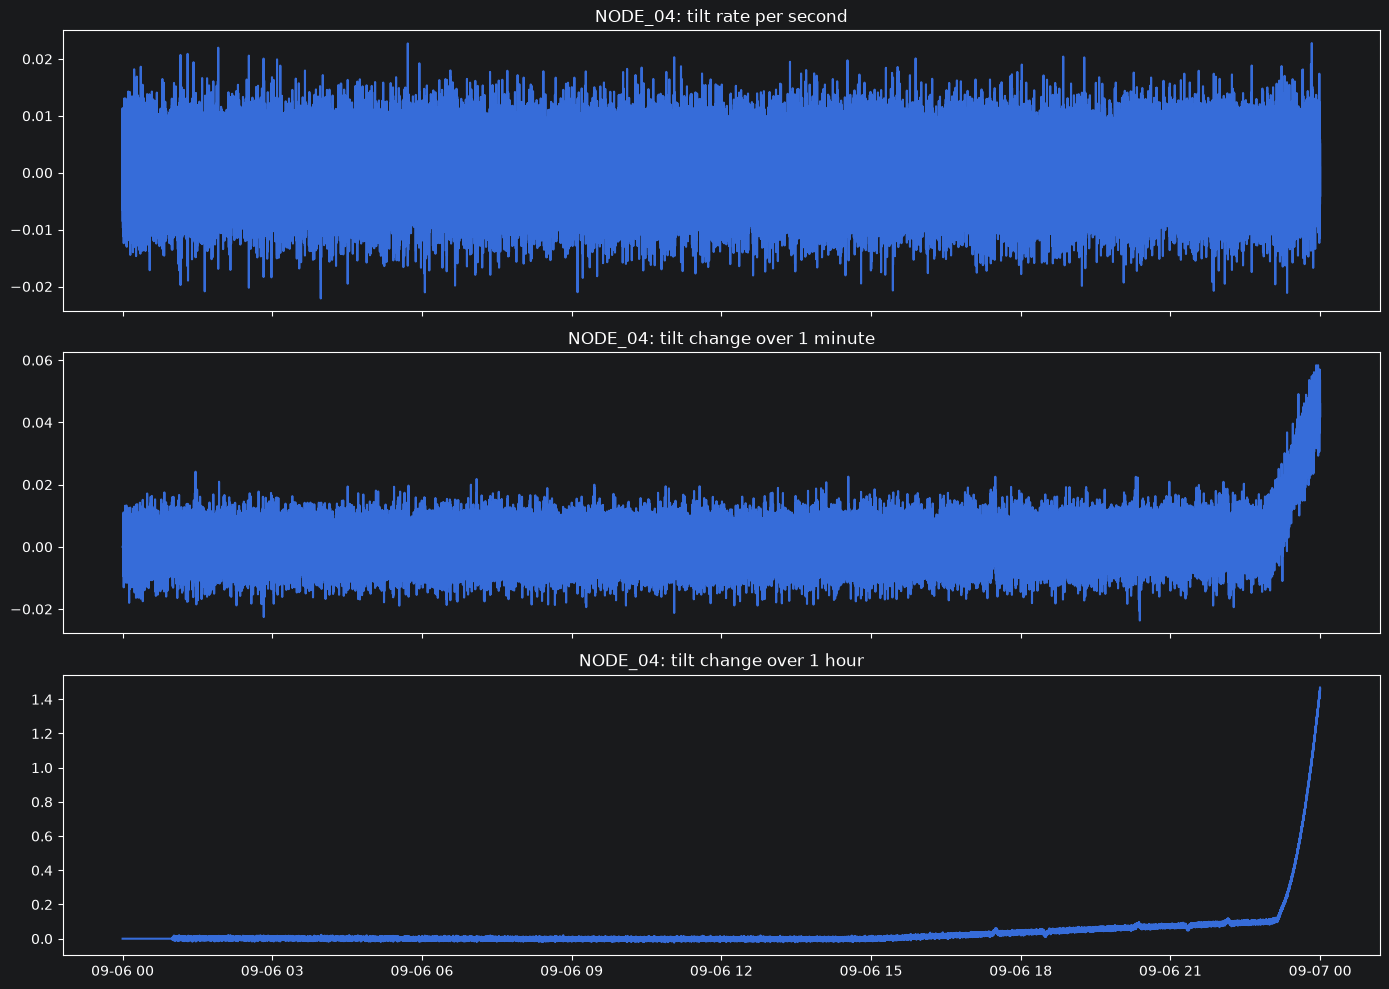

In [99]:
d = features_df[features_df.node_id == "NODE_04"]

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
axes[0].plot(d.timestamp, d.tilt_x_rate_sec)
axes[0].set_title("NODE_04: tilt rate per second")
axes[1].plot(d.timestamp, d.tilt_x_change_1m)
axes[1].set_title("NODE_04: tilt change over 1 minute")
axes[2].plot(d.timestamp, d.tilt_x_change_1h)
axes[2].set_title("NODE_04: tilt change over 1 hour")
plt.tight_layout()
plt.show()

In [100]:
features_df.columns

Index(['node_id', 'timestamp', 'position_x', 'position_y', 'position_z',
       'tilt_x', 'tilt_y', 'vibration_rms', 'vibration_peak', 'crack_width',
       'scenario', 'dt_sec', 'position_z_rate_sec', 'tilt_x_rate_sec',
       'tilt_y_rate_sec', 'crack_width_rate_sec', 'position_z_change_1m',
       'tilt_x_change_1m', 'tilt_y_change_1m', 'crack_width_change_1m',
       'vibration_mean_1m', 'vibration_std_1m', 'crack_growth_1m',
       'position_z_change_1h', 'tilt_x_change_1h', 'tilt_y_change_1h',
       'crack_width_change_1h', 'vibration_mean_1h', 'vibration_std_1h',
       'crack_growth_1h'],
      dtype='str')

## 8. Threshold detector

These are intentionally simple prototype limits. In a real mine they must be replaced by validated engineering limits.

In [101]:
# ============================================================
# THRESHOLD DETECTOR
# ============================================================

THRESHOLDS = {

    # --------------------------------------------------------
    # VERTICAL MOVEMENT / SUBSIDENCE
    # Negative = downward movement
    # --------------------------------------------------------
    #
    # "position_z_rate_sec": {
    #     "watch": -0.0001,
    #     "warning": -0.0005,
    #     "critical": -0.0010,
    # },

    "position_z_change_1m": {
        "watch": -0.002,
        "warning": -0.005,
        "critical": -0.010,
    },

    "position_z_change_1h": {
        "watch": -0.010,
        "warning": -0.030,
        "critical": -0.050,
    },
    #
    # "position_z_change_24h": {
    #     "watch": -0.020,
    #     "warning": -0.050,
    #     "critical": -0.100,
    # },


    # --------------------------------------------------------
    # TILT
    # --------------------------------------------------------
    #
    # "tilt_x_rate_sec": {
    #     "watch": 0.0005,
    #     "warning": 0.0010,
    #     "critical": 0.0020,
    # },
    #
    # "tilt_y_rate_sec": {
    #     "watch": 0.0005,
    #     "warning": 0.0010,
    #     "critical": 0.0020,
    # },

    "tilt_x_change_1m": {
        "watch": 0.01,
        "warning": 0.03,
        "critical": 0.05,
    },

    "tilt_y_change_1m": {
        "watch": 0.01,
        "warning": 0.03,
        "critical": 0.05,
    },

    "tilt_x_change_1h": {
        "watch": 0.03,
        "warning": 0.10,
        "critical": 0.20,
    },

    "tilt_y_change_1h": {
        "watch": 0.03,
        "warning": 0.10,
        "critical": 0.20,
    },

    # "tilt_x_change_24h": {
    #     "watch": 0.05,
    #     "warning": 0.15,
    #     "critical": 0.30,
    # },
    #
    # "tilt_y_change_24h": {
    #     "watch": 0.05,
    #     "warning": 0.15,
    #     "critical": 0.30,
    # },


    # --------------------------------------------------------
    # CRACK GROWTH
    # --------------------------------------------------------

    "crack_growth_1m": {
        "watch": 0.02,
        "warning": 0.05,
        "critical": 0.10,
    },

    "crack_growth_1h": {
        "watch": 0.05,
        "warning": 0.15,
        "critical": 0.30,
    },
    #
    # "crack_growth_24h": {
    #     "watch": 0.10,
    #     "warning": 0.30,
    #     "critical": 0.50,
    # },


    # --------------------------------------------------------
    # VIBRATION
    # --------------------------------------------------------

    "vibration_mean_1m": {
        "watch": 0.50,
        "warning": 0.75,
        "critical": 1.00,
    },

    "vibration_mean_1h": {
        "watch": 0.50,
        "warning": 0.75,
        "critical": 1.00,
    },

    "vibration_std_1m": {
        "watch": 0.10,
        "warning": 0.20,
        "critical": 0.40,
    },

    "vibration_std_1h": {
        "watch": 0.10,
        "warning": 0.20,
        "critical": 0.40,
    },
}


# ============================================================
# FEATURES WHERE NEGATIVE VALUES INDICATE DANGER
# ============================================================

NEGATIVE_DIRECTION_FEATURES = {
    "position_z_rate_sec",
    "position_z_change_1m",
    "position_z_change_1h",
    # "position_z_change_24h",
}


# ============================================================
# CHECK A SINGLE FEATURE
# ============================================================

def threshold_level(value, thresholds, negative_direction=False):
    """
    Return the severity level associated with a feature value.
    """

    if negative_direction:

        if value <= thresholds["critical"]:
            return "CRITICAL"

        elif value <= thresholds["warning"]:
            return "WARNING"

        elif value <= thresholds["watch"]:
            return "WATCH"

        return "NORMAL"

    else:

        if value >= thresholds["critical"]:
            return "CRITICAL"

        elif value >= thresholds["warning"]:
            return "WARNING"

        elif value >= thresholds["watch"]:
            return "WATCH"

        return "NORMAL"


# ============================================================
# APPLY THRESHOLD DETECTOR
# ============================================================

def run_threshold_detector(features_df):
    """
    Evaluate engineered sensor features against predefined
    thresholds for every sensor node and timestamp.

    Returns:
        DataFrame containing threshold severity and reasons.
    """

    results = []

    for _, row in features_df.iterrows():

        reasons = []
        highest_severity = "NORMAL"

        severity_rank = {
            "NORMAL": 0,
            "WATCH": 1,
            "WARNING": 2,
            "CRITICAL": 3,
        }

        # Check every configured feature
        for feature, thresholds in THRESHOLDS.items():

            value = row[feature]

            level = threshold_level(
                value,
                thresholds,
                negative_direction=(
                    feature in NEGATIVE_DIRECTION_FEATURES
                )
            )

            # Keep the highest severity
            if severity_rank[level] > severity_rank[highest_severity]:
                highest_severity = level

            # Store explanation
            if level != "NORMAL":
                reasons.append(
                    f"{feature}={value:.4f} exceeded "
                    f"{level.lower()} threshold"
                )

        results.append({
            "node_id": row["node_id"],
            "timestamp": row["timestamp"],
            "threshold_severity": highest_severity,
            "threshold_triggered": highest_severity != "NORMAL",
            "threshold_reasons": reasons,
        })

    return pd.DataFrame(results)


# ============================================================
# RUN DETECTOR
# ============================================================

threshold_results = run_threshold_detector(features_df)
threshold_triggered = threshold_results[threshold_results.threshold_triggered == True]

threshold_triggered.head()

,node_id,timestamp,threshold_severity,threshold_triggered,threshold_reasons
130,NODE_01,2026-09-06 00:02:10+05:30,WATCH,True,[tilt_y_change_1m=0.0104 exceeded watch thresh...
204,NODE_01,2026-09-06 00:03:24+05:30,WATCH,True,[tilt_y_change_1m=0.0146 exceeded watch thresh...
242,NODE_01,2026-09-06 00:04:02+05:30,WATCH,True,[tilt_y_change_1m=0.0110 exceeded watch thresh...
247,NODE_01,2026-09-06 00:04:07+05:30,WATCH,True,[crack_growth_1m=0.0240 exceeded watch threshold]
248,NODE_01,2026-09-06 00:04:08+05:30,WATCH,True,[tilt_x_change_1m=0.0115 exceeded watch thresh...


In [102]:
print(threshold_results.shape)
print(threshold_triggered.shape)

(432000, 5)
(127930, 5)


## 9. Trend detector

In [103]:
def trend_detector(row):
    checks = [
        ("tilt_x_change_1m", 0.015, "rapid tilt increase"),
        ("tilt_x_change_1h", 0.12, "strong 1-hour tilt increase"),
        ("crack_growth_1h", 0.20, "crack growth over 1 hour"),
        # ("crack_growth_24h", 0.50, "crack growth over 24 hours"),
    ]

    reasons, scores = [], []
    for col, limit, reason in checks:
        value = float(row[col])
        if value > limit:
            reasons.append(reason)
            scores.append(min(value / (3 * limit), 1.0))

    return DetectorResult("trend", max(scores, default=0), bool(reasons), reasons)

## 10. Isolation Forest anomaly detector

Train only on the synthetic **normal period** first. This mimics the idea of learning the mine's normal behavior before asking the model to flag unusual behavior.

In [104]:
ANOMALY_FEATURES = [
    "tilt_x_rate_sec",
    "tilt_y_rate_sec",

    "crack_width_rate_sec",

    "tilt_x_change_1m",
    "tilt_y_change_1m",
    "crack_growth_1m",

    "vibration_mean_1m",
    "vibration_std_1m",

    "position_z_change_1h",

    "tilt_x_change_1h",
    "tilt_y_change_1h",
    "crack_growth_1h",

    "vibration_mean_1h",
    "vibration_std_1h",
]

normal_end = features_df.timestamp.min() + pd.Timedelta(hours=14)
train = features_df[features_df.timestamp < normal_end][ANOMALY_FEATURES]

scaler = StandardScaler()
X_train = scaler.fit_transform(train)

model = IsolationForest(
    n_estimators=150,
    contamination=0.01,
    random_state=42,
    n_jobs=-1
)
model.fit(X_train)

X_all = scaler.transform(features_df[ANOMALY_FEATURES])
raw = -model.decision_function(X_all)

lo, hi = np.percentile(raw, [1, 99])
features_df["anomaly_score"] = np.clip((raw - lo) / (hi - lo), 0, 1)

def anomaly_detector(row):
    score = float(row.anomaly_score)
    triggered = score >= 0.70
    reasons = ["Isolation Forest anomaly"] if triggered else []
    return DetectorResult("anomaly", score, triggered, reasons)

features_df[["node_id", "timestamp", "anomaly_score"]].tail()

,node_id,timestamp,anomaly_score
431995,NODE_05,2026-09-06 23:59:55+05:30,0.977709
431996,NODE_05,2026-09-06 23:59:56+05:30,1.000000
431997,NODE_05,2026-09-06 23:59:57+05:30,0.985703
431998,NODE_05,2026-09-06 23:59:58+05:30,0.988253
431999,NODE_05,2026-09-06 23:59:59+05:30,0.989768


## 11. Visualize anomaly scores

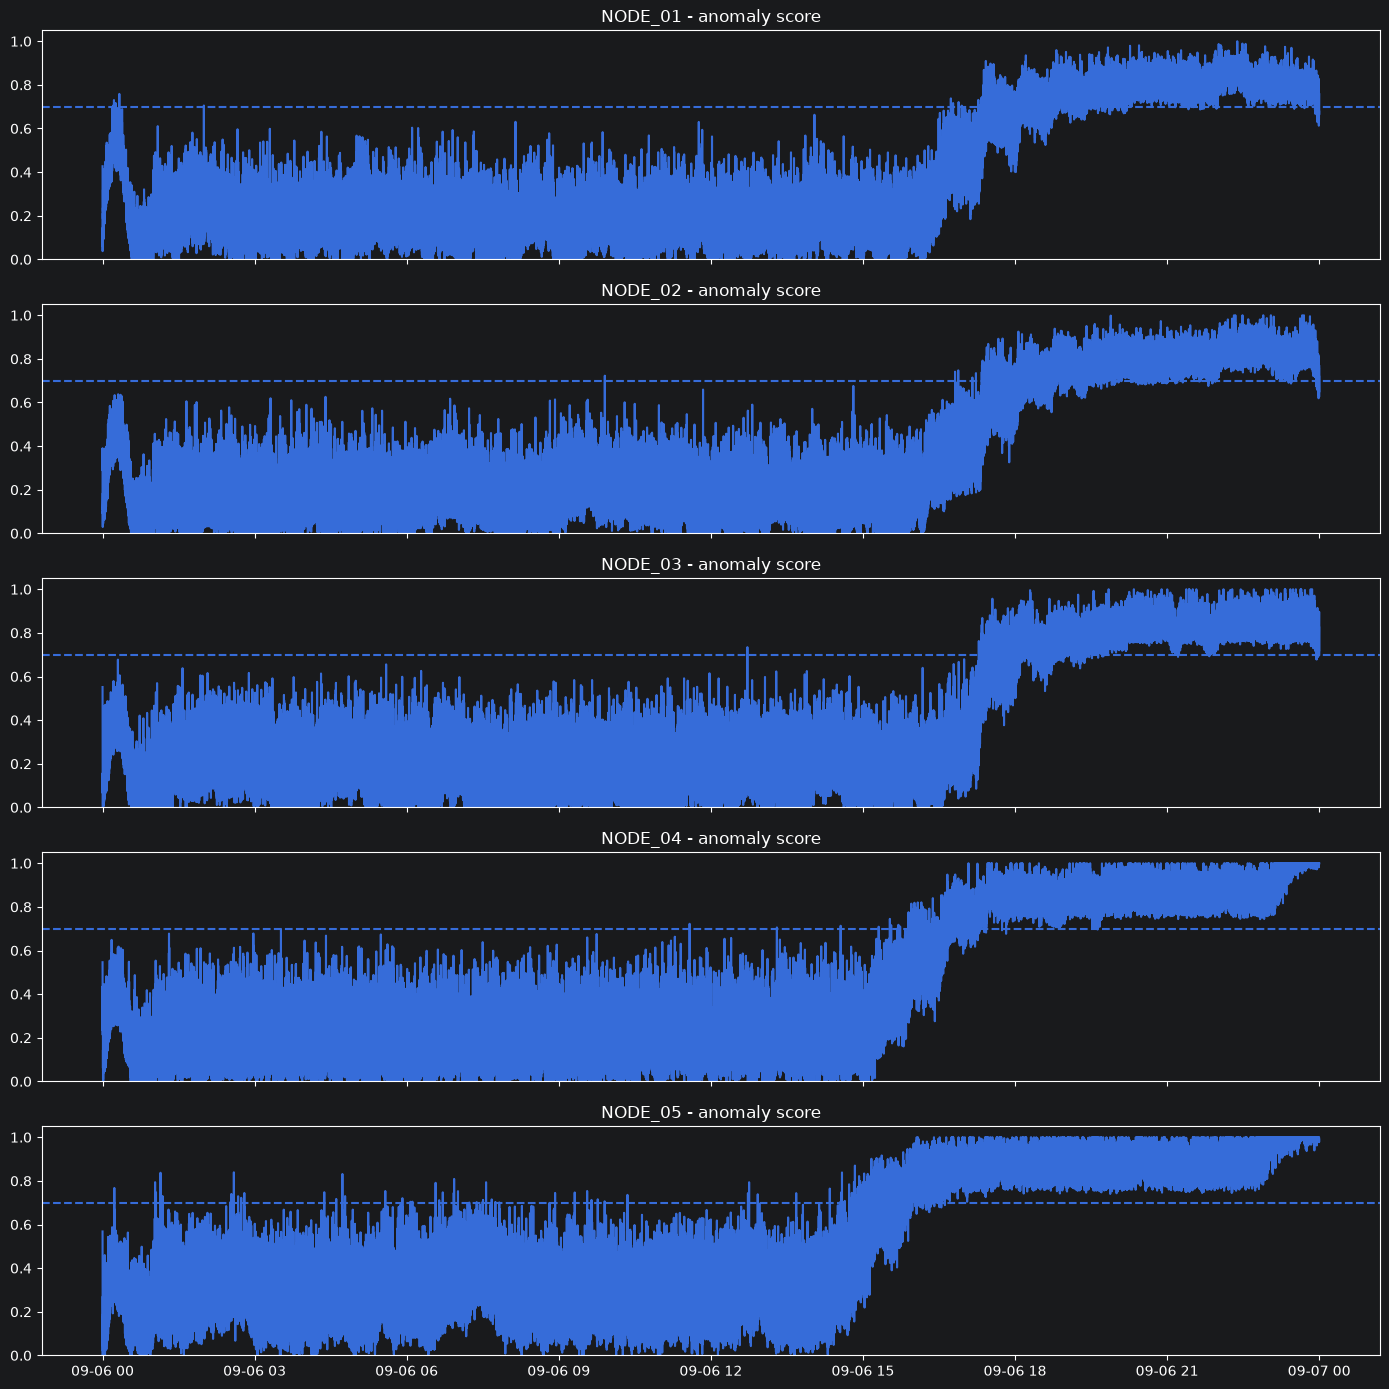

In [105]:
4fig, axes = plt.subplots(5, 1, figsize=(14, 14), sharex=True)

for ax, node in zip(axes, sorted(features_df.node_id.unique())):
    d = features_df[features_df.node_id == node]
    ax.plot(d.timestamp, d.anomaly_score)
    ax.axhline(0.70, linestyle="--")
    ax.set_ylim(0, 1.05)
    ax.set_title(f"{node} - anomaly score")
plt.tight_layout()
plt.show()

## 12. Risk fusion

In [106]:
def fuse_risk(threshold, trend, anomaly, node_id, timestamp):
    score = 100 * (
        0.50 * threshold.score +
        0.25 * trend.score +
        0.25 * anomaly.score
    )

    if score >= 90:
        severity = "CRITICAL"
    elif score >= 75:
        severity = "WARNING"
    elif score >= 50:
        severity = "WATCH"
    else:
        severity = "NORMAL"

    return RiskAssessment(
        node_id=node_id,
        timestamp=timestamp,
        score=float(score),
        severity=severity,
        reasons=threshold.reasons + trend.reasons + anomaly.reasons
    )

def create_alert(risk):
    if risk.severity == "NORMAL":
        return None

    return Alert(
        node_id=risk.node_id,
        timestamp=risk.timestamp,
        severity=risk.severity,
        risk_score=risk.score,
        message=f"{risk.severity} risk at {risk.node_id}: {risk.score:.1f}"
    )

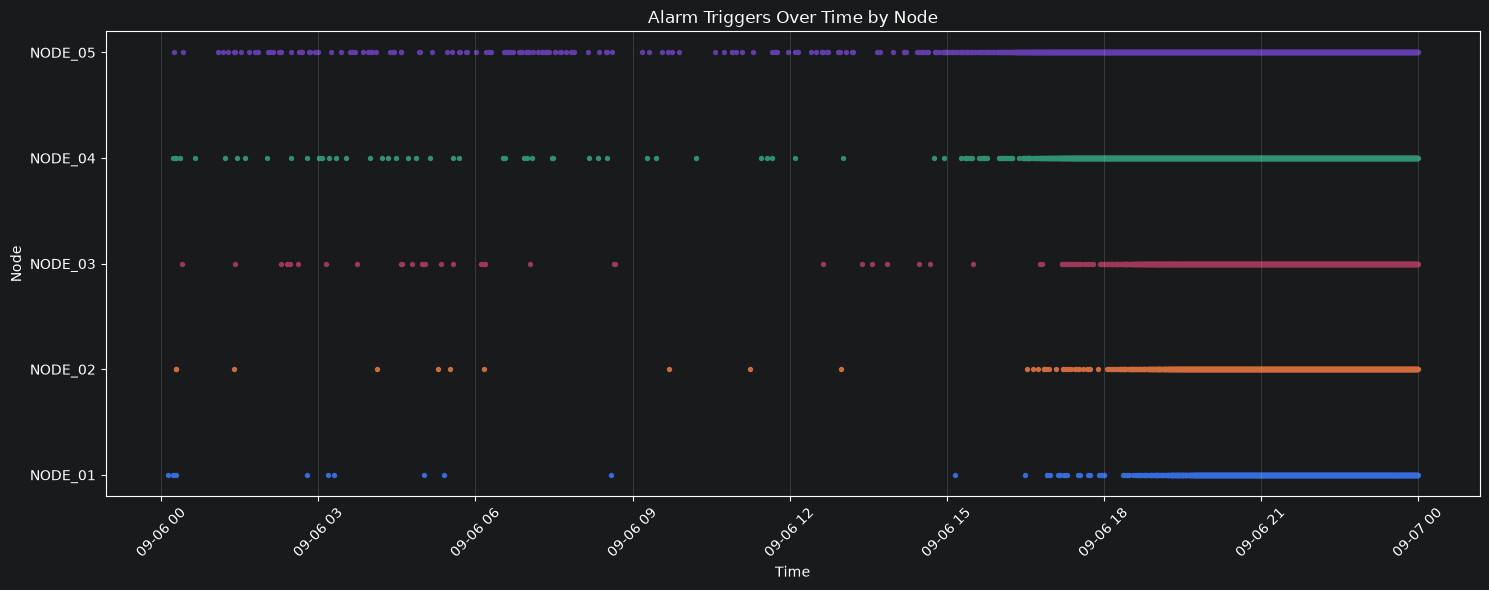

In [107]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

nodes = sorted(alerts_df["node_id"].unique())

for i, node in enumerate(nodes):
    node_alerts = alerts_df[alerts_df["node_id"] == node]

    plt.scatter(
        node_alerts["timestamp"],
        [i] * len(node_alerts),
        s=8
    )

plt.yticks(range(len(nodes)), nodes)
plt.xlabel("Time")
plt.ylabel("Node")
plt.title("Alarm Triggers Over Time by Node")

plt.grid(axis="x", alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 13. End-to-end Live Engine

For notebook speed we evaluate every 10th reading. The production streaming engine can evaluate every incoming reading.

In [82]:
demo = features_df.iloc[::10].copy()

# Run threshold detector on the whole demo dataframe
threshold_results = run_threshold_detector(demo)

risk_records = []
alert_records = []
for i, (_, row) in enumerate(demo.iterrows()):

    threshold_row = threshold_results.iloc[i]

    severity_to_score = {
        "NORMAL": 0.0,
        "WATCH": 0.33,
        "WARNING": 0.66,
        "CRITICAL": 1.0,
    }

    threshold = DetectorResult(
        detector="threshold",
        score=severity_to_score[threshold_row["threshold_severity"]],
        triggered=threshold_row["threshold_triggered"],
        reasons=threshold_row["threshold_reasons"]
    )

    trend = trend_detector(row)
    anomaly = anomaly_detector(row)

    risk = fuse_risk(
        threshold,
        trend,
        anomaly,
        row.node_id,
        row.timestamp
    )
    risk_records.append({
        "node_id": risk.node_id,
        "timestamp": risk.timestamp,
        "risk_score": risk.score,
        "severity": risk.severity,
        "reasons": " | ".join(risk.reasons)
    })

    alert = create_alert(risk)

    if alert:
        alert_records.append({
            "node_id": alert.node_id,
            "timestamp": alert.timestamp,
            "severity": alert.severity,
            "risk_score": alert.risk_score,
            "message": alert.message
        })

risk_df = pd.DataFrame(risk_records)
alerts_df = pd.DataFrame(alert_records)

print("Risk rows:", len(risk_df))
print("Alerts:", len(alerts_df))

Risk rows: 43200
Alerts: 11141


In [80]:
demo = features_df.iloc[::10]

risk_records = []
alert_records = []

for _, row in demo.iterrows():
    threshold = threshold_results.loc[row]
    trend = trend_detector(row)
    anomaly = anomaly_detector(row)

    risk = fuse_risk(
        threshold, trend, anomaly,
        row.node_id, row.timestamp
    )

    risk_records.append({
        "node_id": risk.node_id,
        "timestamp": risk.timestamp,
        "risk_score": risk.score,
        "severity": risk.severity,
        "reasons": " | ".join(risk.reasons)
    })

    alert = create_alert(risk)
    if alert:
        alert_records.append({
            "node_id": alert.node_id,
            "timestamp": alert.timestamp,
            "severity": alert.severity,
            "risk_score": alert.risk_score,
            "message": alert.message
        })

risk_df = pd.DataFrame(risk_records)
alerts_df = pd.DataFrame(alert_records)

print("Risk rows:", len(risk_df))
print("Alerts:", len(alerts_df))

KeyError: "['NODE_01', Timestamp('2026-09-06 00:00:00+0530', tz='UTC+05:30'), 0.09762, 0.063, 0.24092, 0.6069, 1.2075, 'normal', 0.42703171061382245] not in index"

## 14. Alert summary

In [ ]:
if alerts_df.empty:
    print("No alerts generated.")
else:
    print("Alerts by node:")
    display(alerts_df.groupby(["node_id", "severity"]).size().reset_index(name="count"))
    print("\nLast 20 alerts:")
    display(alerts_df.tail(20))

## 15. How this maps to the real repository

After validating the notebook, move the logic into:

```text
engines/live/
├── pipeline.py
├── preprocessing.py
├── features.py
├── detectors/
│   ├── threshold.py
│   ├── trend.py
│   └── anomaly.py
├── fusion/
│   └── risk_score.py
└── alerts/
    └── alert_manager.py
```

Then replace the notebook's CSV input with the ingestion layer's Redis stream.

The important architectural boundary is:

`Redis → ingestion adapter → CleanSensorReading → Live pipeline`

The detectors should not need to know that Redis exists.